# Transformación SECOP II > Procesos

Se define el periodo de análisis, el territorio y los parámetros necesarios para ejecutar la transformación. La escritura en PostgreSQL permanece desactivada mientras se validan los resultados.


## 1. Configuración

Se define el periodo de análisis, el territorio y los parámetros necesarios para ejecutar la transformación. La escritura en PostgreSQL permanece desactivada mientras se validan los resultados.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

NB_DIR = Path("/home/jovyan/work/spark-apps/notebooks")
if not NB_DIR.exists():
    NB_DIR = Path.cwd().resolve()
    if NB_DIR.name == "transformation":
        NB_DIR = NB_DIR.parent
SRC = NB_DIR.parent / "src"
sys.path.insert(0, str(SRC))

from transformation.spark_sesion import _asegurar_pyspark, crear_spark

_asegurar_pyspark()
from pyspark.sql import functions as F
from transformation.controles import controles_criticos_ok, cuadro_control
from transformation.io import leer_procesos_filas, persistir_periodo_procesos, verificar_persistencia
from transformation.jobs.job_procesos import ejecutar
from transformation.procesos import invariantes_adjudicacion

PERIODO = "2026-09"
ESCRIBIR = False  # True solo tras validar conteos
TERRITORIO = "nacional"  # "nacional" o "bogota" (R7, recorte, no Portal)

SALIDAS = NB_DIR / "salidas" / "transformation" / PERIODO / "procesos"
FIGURAS = SALIDAS / "figuras"
SALIDAS.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.titlesize"] = 11

print("Periodo:", PERIODO)
print("ESCRIBIR:", ESCRIBIR)
print("Territorio:", TERRITORIO)
print("Salidas:", SALIDAS)
print("MONGO_URI definido:", bool(os.environ.get("MONGO_URI")))
print("PGUSER definido:", bool(os.environ.get("PGUSER")))


Periodo: 2026-09
ESCRIBIR: False
Territorio: nacional
Salidas: /home/jovyan/work/spark-apps/notebooks/salidas/transformation/2026-09/procesos
MONGO_URI definido: True
PGUSER definido: True


## 2. Comprobación de Spark local y del conector MongoDB

Se verifica el funcionamiento de Spark y su conexión con MongoDB mediante la lectura de una muestra de registros.

In [2]:
spark = crear_spark("nb06-transformacion-procesos")
sc = spark.sparkContext
print("Spark:", spark.version)
print("Master:", sc.master)
print("App:", sc.appName)
print("SPARK_HOME:", os.environ.get("SPARK_HOME"))
print("spark.jars.packages:", spark.sparkContext.getConf().get("spark.jars.packages"))

probe = leer_procesos_filas(spark, PERIODO).limit(5)
print("Columnas (muestra):", probe.columns[:12], "...")
display(probe.select(
    *[c for c in ["socrata_id", "id_del_proceso", "_periodo", "entidad", "departamento_entidad"] if c in probe.columns]
).toPandas())
print("Conector Mongo: lectura OK")


Spark: 3.5.0
Master: local[*]
App: nb06-transformacion-procesos
SPARK_HOME: /usr/local/spark
spark.jars.packages: org.mongodb.spark:mongo-spark-connector_2.12:10.4.0,org.postgresql:postgresql:42.7.3
Columnas (muestra): [':id', '_dataset_id', '_fuente', '_ingestion_ts', '_nivel', '_periodo', 'adjudicado', 'categorias_adicionales', 'ciudad_de_la_unidad_de', 'ciudad_entidad', 'ciudad_proveedor', 'codigo_entidad'] ...


,socrata_id,id_del_proceso,_periodo,entidad,departamento_entidad
0,row-mjib.jpa2-yfrj,CO1.REQ.11012809,2026-09,INSTITUCION EDUCATIVA RURAL PUERTO EL SOL,Putumayo
1,row-8tdu_nuxd.dv9y,CO1.REQ.11124490,2026-09,ICBF REGIONAL ATLANTICO,Atlántico
2,row-qn7a~63qa-f8en,CO1.REQ.11115807,2026-09,DEPARTAMENTO DEL META,Meta
3,row-b82m_fsz9-qxbu,CO1.REQ.11064125,2026-09,SAVIA SALUD EPS - ALIANZA MEDELLIN ANTIOQUIA E...,Antioquia
4,row-q7uw~gjh7-ctc2,CO1.REQ.10997054,2026-09,ALCALDÍA DEL DISTRITO TURÍSTICO Y CULTURAL DE ...,Bolívar


Conector Mongo: lectura OK


## 3. Lectura y validación de filas originales (R1, R2)

Se consultan los registros originales y se verifica la cantidad de filas e identificadores únicos, comparando los resultados con los obtenidos durante el análisis exploratorio.

In [3]:
filas = leer_procesos_filas(spark, PERIODO)
n_filas = filas.count()
n_sid = filas.select("socrata_id").distinct().count()
n_proc_filas = filas.select("id_del_proceso").distinct().count()
print("Filas API:", f"{n_filas:,}".replace(",", "."))
print("socrata_id distintos:", f"{n_sid:,}".replace(",", "."))
print("id_del_proceso distintos:", f"{n_proc_filas:,}".replace(",", "."))
print("¿Filas = socrata_id?:", n_filas == n_sid)

ctrl_src = pd.DataFrame(cuadro_control({
    "filas_api_procesos": n_filas,
    "socrata_id": n_sid,
    "procesos_unicos_en_filas": n_proc_filas,
}))
display(ctrl_src)
ctrl_src.to_csv(SALIDAS / "control_fuente.csv", index=False)


Filas API: 158.830
socrata_id distintos: 158.830
id_del_proceso distintos: 146.947
¿Filas = socrata_id?: True


,control,observado,esperado,diferencia,ok,nota
0,filas_api_procesos,158830,158830.0,0.0,True,coincide con EDA
1,socrata_id,158830,158830.0,0.0,True,coincide con EDA
2,procesos_unicos_en_filas,146947,NaN,NaN,None,sin cifra EDA


## 4. Pipeline de procesos

Se aplican las reglas de transformación para organizar los procesos, identificar registros repetidos, homologar la información territorial y separar las adjudicaciones confiables de las ambiguas.

In [4]:
res = ejecutar(spark, periodo=PERIODO, escribir=False)
proceso = res["proceso"]
adj = res["adjudicacion"]
amb = res["adjudicacion_ambigua"]
pares = res["pares"]
cuadro = pd.DataFrame(res["cuadro"])
print("Tablas derivadas (en memoria, no en PostgreSQL)")
print("proceso:", res["observado"]["procesos"])
print("pares confiables / ambiguos / cartesianos:",
      res["observado"]["pares_adjudicacion_confiables"],
      res["observado"]["pares_adjudicacion_ambiguos"],
      res["observado"]["pares_adjudicacion_cartesianos"])
display(cuadro)
cuadro.to_csv(SALIDAS / "control_reconciliacion.csv", index=False)

disc = cuadro[cuadro["ok"] == False]
if len(disc):
    print("Discrepancias respecto al EDA (no se fuerzan cifras):")
    display(disc)
else:
    print("Todos los controles con cifra EDA coinciden.")


Tablas derivadas (en memoria, no en PostgreSQL)
proceso: 146947
pares confiables / ambiguos / cartesianos: 147075 60 60


,control,observado,esperado,diferencia,ok,nota
0,filas_api_procesos,158830,158830.0,0.0,True,coincide con EDA
1,socrata_id,158830,158830.0,0.0,True,coincide con EDA
2,procesos,146947,146947.0,0.0,True,coincide con EDA
3,pares_adjudicacion_confiables,147075,147075.0,0.0,True,coincide con EDA
4,pares_adjudicacion_ambiguos,60,60.0,0.0,True,coincide con EDA
5,pares_adjudicacion_cartesianos,60,60.0,0.0,True,coincide con EDA
6,pares_sin_awd_no_ambiguos,0,NaN,NaN,None,sin cifra EDA
7,filas_adjudicacion_confiable,147182,NaN,NaN,None,sin cifra EDA
8,filas_adjudicacion_ambigua,60,NaN,NaN,None,sin cifra EDA
9,procesos_campos_variables,0,NaN,NaN,None,sin cifra EDA


Todos los controles con cifra EDA coinciden.


## 5. Conjunto proceso

Se organiza la información para obtener un único registro por proceso, evitando duplicar su precio base y conservando los identificadores de las filas originales. También se identifican valores en cero, negativos y extremos.

In [5]:
print("Columnas proceso:", proceso.columns)
n_var = proceso.filter(F.col("hay_campos_variables")).count()
print("Procesos con algún campo estable variable:", n_var)
if n_var:
    display(proceso.filter(F.col("hay_campos_variables"))
            .select("id_del_proceso", "campos_variables", "n_filas_api")
            .limit(20).toPandas())

print("Marcas precio_base (R6, no son irregularidad):")
marcas = proceso.agg(
    F.sum(F.col("precio_base_cero").cast("int")).alias("cero"),
    F.sum(F.col("precio_base_negativo").cast("int")).alias("negativo"),
    F.sum(F.col("precio_base_extremo").cast("int")).alias("extremo"),
).toPandas()
display(marcas)
marcas.to_csv(SALIDAS / "marcas_precio_base.csv", index=False)

extremos = (proceso.filter(F.col("precio_base_extremo"))
            .select("id_del_proceso", "entidad", "precio_base", "departamento_entidad")
            .orderBy(F.col("precio_base").desc()))
print("Ejemplos precio_base > 1e12:")
display(extremos.limit(10).toPandas())
extremos.toPandas().to_csv(SALIDAS / "precio_base_extremos.csv", index=False)

print("Ejemplos de transformación (5 procesos con más de una fila API):")
ej = (proceso.filter(F.col("n_filas_api") > 1)
      .select("id_del_proceso", "entidad", "departamento_entidad", "ciudad_entidad",
              "precio_base", "n_filas_api", "socrata_ids", "estado_homologacion")
      .orderBy(F.col("n_filas_api").desc())
      .limit(5).toPandas())
display(ej)
ej.to_csv(SALIDAS / "ejemplos_proceso_multifila.csv", index=False)


Columnas proceso: ['id_del_proceso', 'estado_del_procedimiento', 'fecha_de_publicacion_del', 'fecha_de_ultima_publicaci', 'modalidad_de_contratacion', 'entidad', 'nit_entidad', 'departamento_entidad', 'ciudad_entidad', 'precio_base', 'adjudicado', 'referencia_del_proceso', 'duracion', 'unidad_de_duracion', 'ciudad_de_la_unidad_de', '_periodo', '_dataset_id', '_fuente', 'n_filas_api', 'n_socrata_id', 'socrata_ids', 'campos_variables', 'hay_campos_variables', 'url_proceso', 'es_bogota', 'cod_municipio', 'estado_homologacion', 'via_homologacion', 'nombre_municipio_divipola', 'nombre_departamento_divipola', 'departamento_entidad_ausente', 'ciudad_entidad_ausente', 'entidad_ausente', 'adjudicado_ausente', 'precio_base_cero', 'precio_base_negativo', 'precio_base_extremo']
Procesos con algún campo estable variable: 0
Marcas precio_base (R6, no son irregularidad):


,cero,negativo,extremo
0,4191,0,3


Ejemplos precio_base > 1e12:


,id_del_proceso,entidad,precio_base,departamento_entidad
0,CO1.REQ.11134186,UNIDAD DE SERVICIOS PENITENCIARIOS Y CARCELARI...,2.502710e+12,Distrito Capital de Bogotá
1,CO1.REQ.11042287,DIRECCION DE SANIDAD DE LA POLICIA NACIONAL - ...,1.449167e+12,Distrito Capital de Bogotá
2,CO1.REQ.11050646,INSTITUTO DE DEPORTES Y RECREACION DE MEDELLIN,1.159398e+12,Antioquia


Ejemplos de transformación (5 procesos con más de una fila API):


,id_del_proceso,entidad,departamento_entidad,ciudad_entidad,precio_base,n_filas_api,socrata_ids,estado_homologacion
0,CO1.REQ.11077517,INSTITUTO NACIONAL DE SALUD,Distrito Capital de Bogotá,Bogotá,5.352966e+09,8405,row-223j_i7rm~yf7g|row-223u~ujcg~t682|row-22gs...,homologado
1,CO1.REQ.10961130,SENA REGIONAL ANTIOQUIA Grupo Administrativo C...,Antioquia,Itagui,5.845442e+08,90,row-47c8-exbj.dvs4|row-4djn~gzzs_y3cv|row-4fu2...,homologado
2,CO1.REQ.10990189,DEPARTAMENTO DE ANTIOQUIA//,Antioquia,Medellín,9.607148e+09,70,row-3ke6.ntug.4jnp|row-4463_6zvs~sw9q|row-59pv...,homologado
3,CO1.REQ.11111655,FUERZA AEROESPACIAL COLOMBIANA,Distrito Capital de Bogotá,Bogotá,4.659082e+10,51,row-3x7k-9b9t~nykj|row-4eya-e3zp.bypd|row-4gcn...,homologado
4,CO1.REQ.11049429,SANTIAGO DE CALI DISTRITO ESPECIAL - SECRETARI...,Valle del Cauca,Cali,1.079583e+10,49,row-2ggu_jyhd-vbvh|row-2ghj~gx8c-c94u|row-3ecb...,homologado


## 6. Homologación territorial

Se revisa la información de departamentos y municipios utilizando los códigos DIVIPOLA. Los registros sin ubicación definida se mantienen identificados y se permite seleccionar los correspondientes a Bogotá.


,estado_homologacion,n,pct
0,homologado,125160,85.17
1,no_definido,12180,8.29
2,sin_municipio,9013,6.13
3,no_homologado,594,0.40


,via_homologacion,n
0,depto_mpio,105834
1,ambos_ausentes,12180
2,bogota_depto,9828
3,bogota,9450
4,solo_depto,9013
5,sin_cruce,594
6,mpio_unico_nacional,48


Procesos es_bogota (R7): 19.278 (13.12 %)


,departamento_entidad,ciudad_entidad,estado_homologacion,n
0,Antioquia,No Definido,sin_municipio,1592
1,Tolima,No Definido,sin_municipio,988
2,Valle del Cauca,No Definido,sin_municipio,948
3,Santander,No Definido,sin_municipio,781
4,Bolívar,No Definido,sin_municipio,715
5,Caquetá,No Definido,sin_municipio,634
6,Caldas,No Definido,sin_municipio,475
7,Nariño,No Definido,sin_municipio,452
8,La Guajira,No Definido,sin_municipio,392
9,Cundinamarca,No Definido,sin_municipio,371


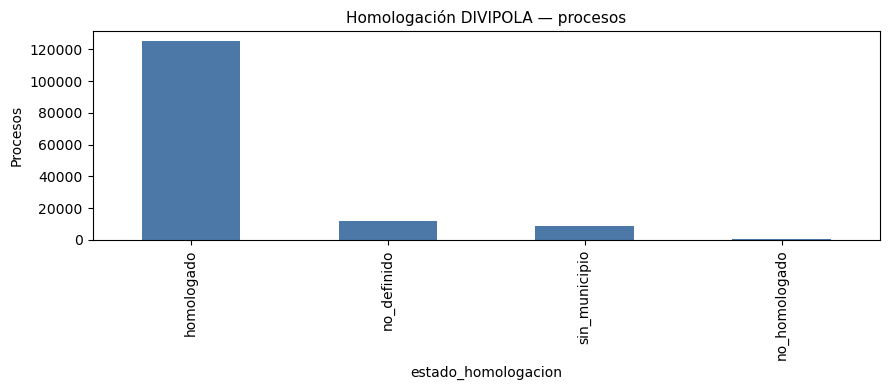

Sin recorte territorial (nacional).


In [6]:
hom = (proceso.groupBy("estado_homologacion")
       .count().withColumnRenamed("count", "n")
       .orderBy(F.col("n").desc()).toPandas())
hom["pct"] = (hom["n"] / hom["n"].sum() * 100).round(2)
display(hom)
hom.to_csv(SALIDAS / "homologacion_estado.csv", index=False)

via = (proceso.groupBy("via_homologacion")
       .count().withColumnRenamed("count", "n")
       .orderBy(F.col("n").desc()).toPandas())
display(via)
via.to_csv(SALIDAS / "homologacion_via.csv", index=False)

n_bog = proceso.filter(F.col("es_bogota")).count()
print("Procesos es_bogota (R7):", f"{n_bog:,}".replace(",", "."),
      f"({100 * n_bog / res['observado']['procesos']:.2f} %)")

no_h = (proceso.filter(F.col("estado_homologacion").isin("no_homologado", "sin_municipio"))
        .groupBy("departamento_entidad", "ciudad_entidad", "estado_homologacion")
        .count().withColumnRenamed("count", "n")
        .orderBy(F.col("n").desc()).limit(20).toPandas())
display(no_h)
no_h.to_csv(SALIDAS / "homologacion_no_cruzados.csv", index=False)

fig, ax = plt.subplots()
hom.set_index("estado_homologacion")["n"].plot(kind="bar", ax=ax, color="#4C78A8")
ax.set_title("Homologación DIVIPOLA — procesos")
ax.set_ylabel("Procesos")
plt.tight_layout()
plt.savefig(FIGURAS / "homologacion_estado.png", dpi=120, bbox_inches="tight")
plt.show()

if TERRITORIO == "bogota":
    proceso_view = proceso.filter(F.col("es_bogota"))
    print("Recorte Bogotá aplicado a las vistas siguientes:", proceso_view.count())
else:
    proceso_view = proceso
    print("Sin recorte territorial (nacional).")


## 7. Adjudicaciones confiables y ambiguas

Se verifica la relación entre los proveedores y los valores adjudicados. Las adjudicaciones ambiguas se identifican por separado y sus valores no se incluyen en las sumas para evitar duplicidades.


Pares (grano proceso + id_adjudicacion): 147135
Confiables: 147075
Ambiguos: 60
Cartesianos: 60
Sin AWD y no ambiguos (no entran en tfm.adjudicacion): 0
Filas tfm.adjudicacion (proveedor+valor confiables): 147182
Filas tfm.adjudicacion_ambigua: 60
Ejemplos ambiguos (valores listados, no sumados):


,id_del_proceso,id_adjudicacion,n_filas_api,n_proveedores,n_valores,cartesiano,motivo,proveedores,valores,suma_valores,socrata_ids
0,CO1.REQ.11077517,CO1.AWD.2714705,8405,41,41,True,cartesiano_proveedor_valor,700097041 | 700483050 | 700489032 | 700743115 ...,1.0121783E8 | 1.02099347E8 | 1.07317648E8 | 1....,no aplicada,row-223j_i7rm~yf7g|row-223u~ujcg~t682|row-22gs...
1,CO1.REQ.10961130,CO1.AWD.2704464,72,4,9,True,cartesiano_proveedor_valor,701940041 | 702001041 | 703835827 | 713294221,1.09282555E8 | 1.21403132E8 | 1.5535486E7 | 1....,no aplicada,row-47c8-exbj.dvs4|row-4djn~gzzs_y3cv|row-4fu2...
2,CO1.REQ.10990189,CO1.AWD.2731347,70,5,7,True,cartesiano_proveedor_valor,700053044 | 700750110 | 701123069 | 716466065 ...,1.088E9 | 2.29881985E8 | 2.9340202E8 | 4.8E8 |...,no aplicada,row-3ke6.ntug.4jnp|row-4463_6zvs~sw9q|row-59pv...
3,CO1.REQ.11111655,CO1.AWD.2730491,50,5,10,True,cartesiano_proveedor_valor,700284011 | 701273187 | 701453243 | 702375288 ...,1.402613422E9 | 1.474804E9 | 3.7351224E10 | 4....,no aplicada,row-3x7k-9b9t~nykj|row-4eya-e3zp.bypd|row-4gcn...
4,CO1.REQ.11072406,CO1.AWD.2730259,45,5,9,True,cartesiano_proveedor_valor,700811045 | 700942212 | 701012155 | 701073272 ...,1.5531519E7 | 1.817165E7 | 2363147.0 | 3.50992...,no aplicada,row-2qw9_3bwb-vsir|row-3arf.x2me~56u6|row-4urn...
5,CO1.REQ.11015109,CO1.AWD.2711018,30,6,5,True,cartesiano_proveedor_valor,704027440 | 704323922 | 704403419 | 704537513 ...,1600000.0 | 2000000.0 | 3000000.0 | 4000000.0 ...,no aplicada,row-26an_rxiy.973v|row-49bx~ty9s_i29a|row-522w...
6,CO1.REQ.11036194,CO1.AWD.2707910,30,6,5,True,cartesiano_proveedor_valor,702188483 | 703568584 | 703628206 | 707271177 ...,1.078E8 | 1.176E8 | 1.78234E8 | 8.33E7 | 9.8E7,no aplicada,row-23v9~6um2.ynzb|row-5i62~wsp8.fqyz|row-7b3n...
7,CO1.REQ.11114661,CO1.AWD.2718856,27,3,9,True,cartesiano_proveedor_valor,700097041 | 702308206 | 713294221,1.1603619E7 | 1.2042135E7 | 1.7432054E7 | 1.80...,no aplicada,row-6t38~gwcc.vcec|row-7356_b9gn-f2nd|row-7rf3...


Ejemplos confiables con más de una fila API:


,id_del_proceso,id_adjudicacion,codigo_proveedor,nombre_del_proveedor,valor_total_adjudicacion,n_filas_api,socrata_ids
0,CO1.REQ.10922197,CO1.AWD.2696008,705291821,EMPRESA DE SERVICIOS PUBLICOS DE SABANETA E.S.P.,610336482.0,2,row-4r29_tk9q~yeq3|row-rgvm.rr3j_dsmu
1,CO1.REQ.10944000,No Adjudicado,_sin_proveedor,No Definido,0.0,9,row-afsf.maq7_pynj|row-bpmc_8hg6~e4y6|row-cvih...
2,CO1.REQ.10958642,No Adjudicado,_sin_proveedor,No Definido,0.0,2,row-f2ve-gpnp~4kcg|row-q44d~hu5x.y73y
3,CO1.REQ.10959084,No Adjudicado,_sin_proveedor,No Definido,0.0,2,row-7hn2.jzfe~vcks|row-nerp~fkjs~6pva
4,CO1.REQ.10960250,No Adjudicado,_sin_proveedor,No Definido,0.0,2,row-9b65-kvzq~c3rh|row-grg3_i6gx~w922
5,CO1.REQ.10961130,CO1.AWD.2722852,701940041,SUMINISTROS MAYBE SAS,8838707.0,2,row-gyhu.iwuf.b88n|row-jzgu~zq6h~xd56
6,CO1.REQ.10961130,CO1.AWD.2722957,701940041,SUMINISTROS MAYBE SAS,76634200.0,2,row-6gjp_9yb7_fjyz|row-sz2w.zia7~qvmh
7,CO1.REQ.10961253,CO1.AWD.2695054,722528411,CEFORIV SAS,19650000.0,2,row-cs6j_ryhk_kktg|row-kbf3_micj-6sp2


Valores > 0 en confiables (sin cartesianos): 6459
Mediana valores > 0: 48375800.0


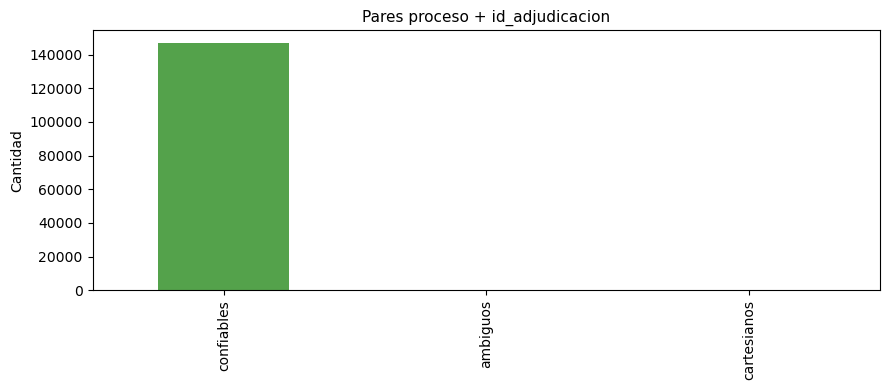

In [7]:
print("Pares (grano proceso + id_adjudicacion):", pares.count())
print("Confiables:", pares.filter(F.col("confiable")).count())
print("Ambiguos:", pares.filter(F.col("ambiguo")).count())
print("Cartesianos:", pares.filter(F.col("cartesiano")).count())
print("Sin AWD y no ambiguos (no entran en tfm.adjudicacion):",
      pares.filter(F.col("sin_awd") & (~F.col("ambiguo"))).count())
print("Filas tfm.adjudicacion (1 por par confiable):", adj.count())
print("Filas tfm.adjudicacion_ambigua:", amb.count())
print("tipo_grano en confiables:")
adj.groupBy("tipo_grano").count().orderBy("tipo_grano").show(truncate=False)
print("valor_usable True:", adj.filter(F.col("valor_usable")).count())
print("Invariantes:", invariantes_adjudicacion(adj, amb) or "ok")

ej_amb = (amb.select("id_del_proceso", "id_adjudicacion", "n_filas_api",
                     "n_proveedores", "n_valores", "cartesiano", "motivo",
                     "proveedores", "valores", "suma_valores", "socrata_ids")
          .orderBy(F.col("n_filas_api").desc()).limit(8).toPandas())
print("Ejemplos ambiguos (valores listados, no sumados):")
display(ej_amb)
ej_amb.to_csv(SALIDAS / "ejemplos_adjudicacion_ambigua.csv", index=False)
amb.toPandas().to_csv(SALIDAS / "adjudicacion_ambigua.csv", index=False)

ej_ok = (adj.filter(F.col("n_filas_api") > 1)
         .select("id_del_proceso", "id_adjudicacion", "codigo_proveedor",
                 "nombre_del_proveedor", "valor_total_adjudicacion",
                 "n_filas_api", "socrata_ids")
         .limit(8).toPandas())
print("Ejemplos confiables con más de una fila API:")
display(ej_ok)
ej_ok.to_csv(SALIDAS / "ejemplos_adjudicacion_confiable.csv", index=False)

val_ok = adj.filter(F.col("valor_total_adjudicacion") > 0).select("valor_total_adjudicacion")
n_val_ok = val_ok.count()
print("Valores > 0 en confiables (sin cartesianos):", n_val_ok)
if n_val_ok:
    print("Mediana valores > 0:", val_ok.approxQuantile("valor_total_adjudicacion", [0.5], 0.01)[0])

fig, ax = plt.subplots()
pd.Series({
    "confiables": res["observado"]["pares_adjudicacion_confiables"],
    "ambiguos": res["observado"]["pares_adjudicacion_ambiguos"],
    "cartesianos": res["observado"]["pares_adjudicacion_cartesianos"],
}).plot(kind="bar", ax=ax, color=["#54A24B", "#E45756", "#F58518"])
ax.set_title("Pares proceso + id_adjudicacion")
ax.set_ylabel("Cantidad")
plt.tight_layout()
plt.savefig(FIGURAS / "pares_adjudicacion.png", dpi=120, bbox_inches="tight")
plt.show()


## 8. Descriptivos del conjunto proceso


,departamento_entidad,n,pct
0,Distrito Capital de Bogotá,19278,13.12
1,Antioquia,18627,12.68
2,No Definido,12180,8.29
3,Valle del Cauca,11114,7.56
4,Santander,7539,5.13
5,Cundinamarca,7004,4.77
6,Bolívar,6794,4.62
7,Magdalena,5463,3.72
8,Boyacá,4984,3.39
9,Nariño,4815,3.28


,modalidad_de_contratacion,n,pct
0,Contratación régimen especial,67851,46.17
1,Contratación directa,65473,44.56
2,Mínima cuantía,4393,2.99
3,Selección Abreviada de Menor Cuantía,2853,1.94
4,Solicitud de información a los Proveedores,2455,1.67
5,Selección abreviada subasta inversa,1313,0.89
6,Contratación régimen especial (con ofertas),832,0.57
7,Contratación Directa (con ofertas),753,0.51
8,Concurso de méritos abierto,458,0.31
9,Licitación pública,267,0.18


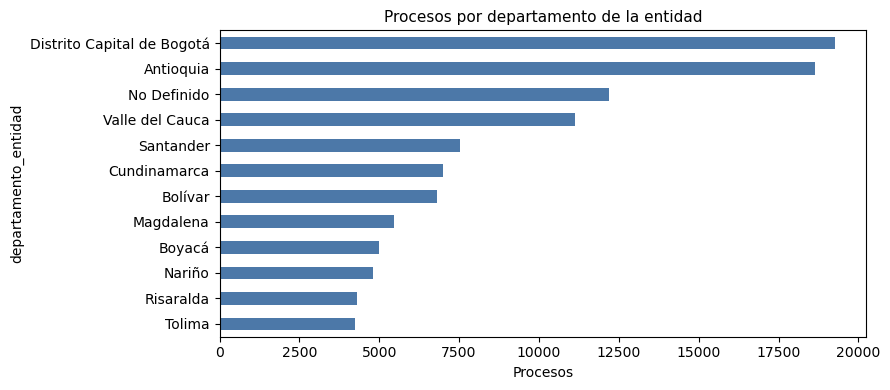

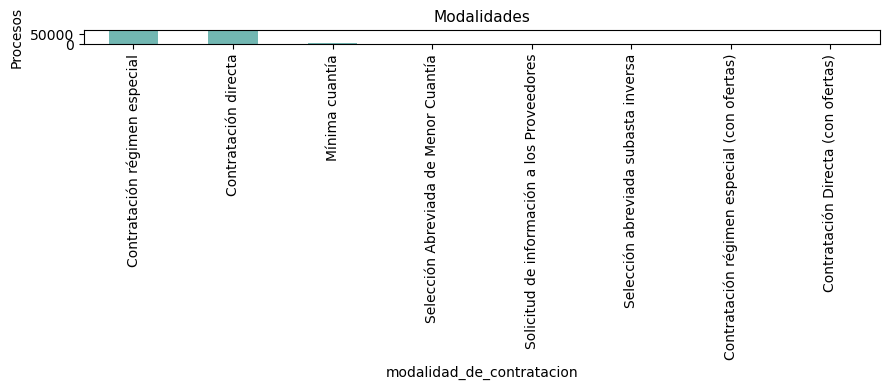

In [8]:
depto = (proceso_view.groupBy("departamento_entidad")
         .count().withColumnRenamed("count", "n")
         .orderBy(F.col("n").desc()).toPandas())
depto["pct"] = (depto["n"] / depto["n"].sum() * 100).round(2)
display(depto.head(15))
depto.to_csv(SALIDAS / "departamentos.csv", index=False)

mod = (proceso_view.groupBy("modalidad_de_contratacion")
       .count().withColumnRenamed("count", "n")
       .orderBy(F.col("n").desc()).toPandas())
mod["pct"] = (mod["n"] / mod["n"].sum() * 100).round(2)
display(mod.head(12))
mod.to_csv(SALIDAS / "modalidades.csv", index=False)

fig, ax = plt.subplots()
depto.head(12).set_index("departamento_entidad")["n"].plot(kind="barh", ax=ax, color="#4C78A8")
ax.invert_yaxis()
ax.set_title("Procesos por departamento de la entidad")
ax.set_xlabel("Procesos")
plt.tight_layout()
plt.savefig(FIGURAS / "departamentos.png", dpi=120, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots()
mod.head(8).set_index("modalidad_de_contratacion")["n"].plot(kind="bar", ax=ax, color="#72B7B2")
ax.set_title("Modalidades")
ax.set_ylabel("Procesos")
plt.tight_layout()
plt.savefig(FIGURAS / "modalidades.png", dpi=120, bbox_inches="tight")
plt.show()


## 9. Persistencia

Se define el procedimiento para almacenar los resultados en PostgreSQL, incluyendo las validaciones necesarias antes de publicar la información. En esta ejecución, la escritura permanece desactivada.


In [9]:
print("ESCRIBIR =", ESCRIBIR)
print("Tablas que quedarían en esquema tfm:")
for t, df in [("proceso", proceso), ("adjudicacion", adj),
              ("adjudicacion_ambigua", amb), ("proceso_control", res["control"])]:
    print(f"  tfm.{t}: {df.count()} filas, {len(df.columns)} columnas")

if ESCRIBIR:
    if not controles_criticos_ok(res["cuadro"]):
        print("Control critico distinto del EDA. No se escribe.")
    elif res.get("fallos_invariante"):
        print("Invariantes fallidas. No se escribe:", res["fallos_invariante"])
    else:
        persistir_periodo_procesos(proceso, adj, amb, res["control"], PERIODO)
        verif = verificar_persistencia(spark, PERIODO, {
            "proceso": res["observado"]["procesos"],
            "adjudicacion": res["observado"]["filas_adjudicacion_confiable"],
            "adjudicacion_ambigua": res["observado"]["filas_adjudicacion_ambigua"],
        })
        display(pd.DataFrame(verif))
        print("Escritura tfm.* hecha.")
else:
    print("Sin escritura. Para persistir: ESCRIBIR = True y volver a ejecutar esta celda, o ESCRIBIR=true en job_procesos.py")

pd.DataFrame([{
    "tabla": "tfm.proceso",
    "filas": res["observado"]["procesos"],
    "grano": "periodo + id_del_proceso",
}, {
    "tabla": "tfm.adjudicacion",
    "filas": res["observado"]["filas_adjudicacion_confiable"],
    "grano": "periodo + proceso + id_adjudicacion (confiable; no explode proveedor-valor)",
}, {
    "tabla": "tfm.adjudicacion_ambigua",
    "filas": res["observado"]["filas_adjudicacion_ambigua"],
    "grano": "periodo + proceso + id_adjudicacion (no 1:1; sin suma)",
}, {
    "tabla": "tfm.proceso_control",
    "filas": len(cuadro),
    "grano": "corrida",
}]).to_csv(SALIDAS / "tablas_pendientes_tfm.csv", index=False)


ESCRIBIR = False
Tablas que quedarían en esquema tfm:
  tfm.proceso: 146947 filas, 37 columnas
  tfm.adjudicacion: 147182 filas, 11 columnas
  tfm.adjudicacion_ambigua: 60 filas, 16 columnas
  tfm.proceso_control: 11 filas, 9 columnas
Sin escritura. Para persistir: ESCRIBIR = True y volver a ejecutar esta celda, o ESCRIBIR=true en job_procesos.py


## 10. Cierre


In [10]:
print("Mongo procesos_filas_api: solo lectura.")
print("Esquema public: no se toca.")
print("Contratos y DANE: no implementados en este notebook.")
spark.stop()
print("SparkSession cerrada.")


Mongo procesos_filas_api: solo lectura.
Esquema public: no se toca.
Contratos y DANE: no implementados en este notebook.
SparkSession cerrada.
